# 06: BFM replication (Blanchet et al. 2022)

Skeleton to replicate BFM for Chile 2017 and apply to CASEN 2022. Full Stata reference: `https://github.com/ignacio-flores/bfmcorr` + `gpinter` (`https://wid.world/gpinter/`).

The BFM steps (fractal grid, gpinter, calibration, support expansion) live in `source/bfm.py`; income is expressed as ANNUAL PER ADULT (`ytotcorh` x 12 / adults 20+) to be comparable with the SII tabulation.

In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from pathlib import Path
from utils import load_root

ROOT = load_root()
from source.shares import weighted_shares
from source.sii import load_sii_pub_total, sii_for_at
from source.figures import plot_bfm_fractal_bins, plot_bfm_theta_Theta_real, save_fig
from source.bfm import (interpolate_tax_tabulation, estimate_merging_point, calibrate_weights,
                        expand_support, fractal_percentiles_from, _fractal_percentiles, _fractal_thresholds)


[utils] Project root loaded successfully: /home/choroy/Documents/doctorado/S4/ENECO894/problem-set


## 0. Fractal bins


This cell visualizes the **fractal binning**.

It calls `plot_bfm_fractal_bins` from `source/figures.py` (the 99 bins $0$--$99\%$ plus 9 bins $\times$ 0.1/0.01/0.001 pp) and saves `figures/p3/bfm_fractal_bins.pdf` used in the report. Each row zooms into the red-hatched tail of the row above, so resolution grows where $\theta(y)$ is expected to fall.

/tmp/ipykernel_210054/1645219120.py:3: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.32, 0, 0.96, 0.92])


saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set/figures/p3/bfm_fractal_bins.pdf


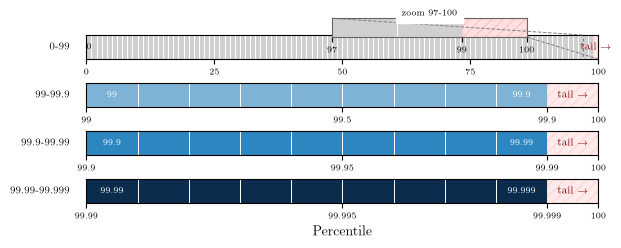

In [10]:
fig = plt.figure(figsize=(8, 2))
fig, axes = plot_bfm_fractal_bins(fig)
plt.tight_layout(rect=[0.32, 0, 0.96, 0.92])
save_fig(ROOT / "figures/p3/bfm_fractal_bins.pdf", fig)
plt.show()


## 1. Load inputs for Chile 2017 and 2022

- **Survey:** `data/processed/casen_2017_hh.parquet` and `casen_2022_hh.parquet` (from `05_data_exploration.ipynb`, one row per `folio+hogar` via `to_household`)
  - `ytotcorh` = total household income (corrected for non-response)
  - `expr` = expansion factor (survey weight)
  - `folio+hogar` = household identifier (one row per household)
- **Tax tabulation:** SII brackets from `data/SII/PUB_Total.xlsb` (SII, personas naturales, 2005--2024), Consolidated `cons_n`/`cons_renta` by UTA bracket, filtered to commercial years 2017 (AT 2018) and 2022 (AT 2023) via `load_sii_pub_total` / `sii_for_at` in `source/sii.py`. No Flores et al. (2020) tabulation was used (the `bfmcorr` repo only contained the Brazil example).


**Load survey inputs**

We use the household-level CASEN files built in `05_data_exploration.ipynb` where,

- `ytotcorh` = total household income, 
- `expr` = expansion factor, 
- one row per `folio+hogar` via `to_household`

These are the $y_i, d_i$ in Eq. 14


In [11]:
def load_hh(year):
    hh = pd.read_parquet(ROOT / f"data/processed/casen_{year}_hh.parquet")
    ap = ROOT / f"data/processed/casen_{year}_adults.parquet"
    if ap.exists():
        ad = pd.read_parquet(ap)
    else:
        p = pd.read_stata(ROOT / f"data/CASEN/casen_{year}.dta", columns=["folio", "hogar", "edad"])
        p["adult"] = (pd.to_numeric(p["edad"], errors="coerce") >= 20).astype(float)
        ad = p.groupby(["folio", "hogar"], as_index=False)["adult"].sum()
        ad.to_parquet(ap, index=False)
    for d in (hh, ad):
        d["folio"] = pd.to_numeric(d["folio"]).astype("int64")
        d["hogar"] = pd.to_numeric(d["hogar"]).astype("int64")
    hh = hh.merge(ad, on=["folio", "hogar"], how="left")
    hh["adult"] = hh["adult"].fillna(1).clip(lower=1)
    # annual income per adult, weight = expansion factor x adults (see 03.tex §Normalization of units)
    hh["y"] = hh["ytotcorh"].astype(float) * 12.0 / hh["adult"]
    hh["w"] = hh["expr"].astype(float) * hh["adult"]
    ok = np.isfinite(hh["y"]) & np.isfinite(hh["w"]) & (hh["y"] > 0) & (hh["w"] > 0)
    print(f"{year}: {len(hh)} hogares, {int((~ok).sum())} descartados, adultos medios={hh['adult'].mean():.2f}")
    return hh[ok].reset_index(drop=True)

hh17 = load_hh(2017)
hh22 = load_hh(2022)
print(hh17.shape, hh22.shape)
hh17.head()


2017: 70948 hogares, 90 descartados, adultos medios=2.25
2022: 72053 hogares, 190 descartados, adultos medios=2.12
(70858, 10) (71863, 10)


,folio,hogar,ytotcorh,expr,tot_per_h,region,area,adult,y,w
0,110110020201,1,250000,23,1,1,1,1.0,3000000.0,23.0
1,110110020301,1,211091,29,1,1,1,1.0,2533092.0,29.0
2,110110020401,1,593500,46,2,1,1,2.0,3561000.0,92.0
3,110110020501,1,341667,42,3,1,1,2.0,2050002.0,84.0
4,110110020601,1,463333,32,2,1,1,2.0,2779998.0,64.0


**Build tax tabulations**: parses the double header (rows 6--7) of `PUB_Total.xlsb` (SII 2005--2024) into tidy `cons_n`/`cons_renta` (Consolidated). 

We filter commercial years 2017 (AT 2018) and 2022 (AT 2023) with `sii_for_at` and save `data/SII/sii_2017_tabulation.csv` for `bfmcorr`/`gpinter`. These $w_k$ and brackets define the $y_k$ in the histogram.

In [12]:
# Build BFM tax files from PUB_Total.xlsb (no manual CSV needed)
raw, cleaned = load_sii_pub_total(ROOT / 'data/SII/PUB_Total.xlsb')

# Save BFM-ready CSVs for AT 2018 (com. 2017) and AT 2023 (com. 2022)

out_dir = ROOT / "data/SII"
out_dir.mkdir(parents=True, exist_ok=True)

for at_com in [2017, 2022]:
    df_at = sii_for_at(cleaned, at_com)

    # BFM expects brackets with threshold, n, total income
    bfm = df_at[["tramo", "cons_n", "cons_renta"]]
    bfm = bfm.rename(columns={"tramo":"bracket",
                              "cons_n":"n","cons_renta":
                              "total_income_mm"})
    
    # save csv
    csv = out_dir / f"sii_{at_com}_tabulation.csv"
    bfm.to_csv(csv, index=False)
    
    print(f"saved {csv} -> {len(bfm)} brackets")
    display(bfm.head())

tax2017 = sii_for_at(cleaned, 2017)
tax2022 = sii_for_at(cleaned, 2022)


saved /home/choroy/Documents/doctorado/S4/ENECO894/problem-set/data/SII/sii_2017_tabulation.csv -> 7 brackets


,bracket,n,total_income_mm
104,"Tramo 1 - 0 a 13,5 UTA (Exento)",7521748,20780170.0
105,"Tramo 2 - 13,5 a 30 UTA (Tasa 4%)",1602936,17606393.3
106,Tramo 3 - 30 a 50 UTA (Tasa 8%),451646,9675282.0
107,"Tramo 4 - 50 a 70 UTA (Tasa 13,5%)",171242,5668327.8
108,Tramo 5 - 70 a 90 UTA (Tasa 23%),85817,3818661.2


saved /home/choroy/Documents/doctorado/S4/ENECO894/problem-set/data/SII/sii_2022_tabulation.csv -> 8 brackets


,bracket,n,total_income_mm
141,"Tramo 1 - 0 a 13,5 UTA (Exento)",8445792,32634187.8
142,"Tramo 2 - 13,5 a 30 UTA (Tasa 4%)",1950483,27927090.1
143,Tramo 3 - 30 a 50 UTA (Tasa 8%),539187,15035930.4
144,"Tramo 4 - 50 a 70 UTA (Tasa 13,5%)",196432,8461577.9
145,Tramo 5 - 70 a 90 UTA (Tasa 23%),93151,5390994.0


## 2. gpinter interpolation + merging point y*



**Estimate $y^*$**: `estimate_merging_point(y,w,tax_n)` computes $$\tilde\theta_k=\text{share}_{s,k}/w_k$$ share survey / share tax ($width_k$ cancels), $$\hat\Theta(y)=(1-\hat F_s)/(1-\hat F_t),$$ then smooths $\tilde\theta$ to $\hat\theta$ via antitonic regression $$\min \sum w_k(\hat\theta_k-\tilde\theta_k)^2$$ s.t. decreasing, PAVA. $$k^*=\min\{k:\hat\theta_k<\hat\Theta_k\}$$ gives $y^*=y_{k^*}$. The printed `tilde`/`theta_hat` let you verify monotonicity.

In [13]:
results = {}
for name, hh, at in [("2017", hh17, 2017), ("2022", hh22, 2022)]:
    tax_df = sii_for_at(cleaned, at)
    tax_n = tax_df["cons_n"].values
    tax_renta = tax_df["cons_renta"].values
    tramos = tax_df["tramo"].tolist()
    y_star, tilde, theta_hat, Theta_hat, yk = estimate_merging_point(
        hh["y"].values, hh["w"].values, tax_n, tax_renta=tax_renta,
        tax_tramos=tramos, at_comercial=at, fractal=True)
    yk_edges, tax_share, p_start = _fractal_thresholds(tax_n, tax_renta, tramos, at, float(hh["w"].sum()))
    n_above = int((hh["y"] >= y_star).sum())
    print(f"{name}: y* = {y_star:,.0f} CLP/anio | bins={len(yk)} | obs sobre y*={n_above} | p_start={p_start:.4f}")
    results[name] = dict(hh=hh, at=at, tax_n=tax_n, tax_renta=tax_renta, tramos=tramos,
                         y_star=y_star, tilde=tilde, theta_hat=theta_hat, Theta_hat=Theta_hat,
                         yk=yk, tax_share=tax_share, p_start=p_start)


2017: y* = 68,030,172 CLP/anio | bins=45 | obs sobre y*=111 | p_start=0.8187
2022: y* = 189,996,494 CLP/anio | bins=46 | obs sobre y*=12 | p_start=0.8038


## 3. Calibration + expanding support


**Calibration (reweighting)**:

`calibrate_weights(y,w,y^*,tax_n, alpha=5)` implements truncated linear calibration: it finds $k^*$ for $y^*$, computes $\text{tax\_share}_{\ge k^*}$ vs $\text{survey\_share}_{\ge y^*}$, sets `factor_above = tax_share_above / share_s_above` (clipped to $[1/\alpha,\alpha]$) and `factor_below` to preserve total population, producing $w_i^{cal}$. This matches the tax mass above $y^*$ while keeping demographic totals (cf. `03.tex` Algorithm~\ref{alg:bfm} Step 2).

In [14]:
for name, r in results.items():
    hh = r["hh"]
    w_cal = calibrate_weights(hh["y"].values, hh["w"].values, r["y_star"], r["tax_n"], alpha=5,
                              yk=r["yk"], tax_share=r["tax_share"], f_t_start=r["p_start"])
    y_exp = expand_support(hh["y"].values, w_cal, r["y_star"], r["tax_n"], r["tax_renta"],
                           r["tramos"], r["at"])
    hh["w_bfm"] = w_cal
    hh["y_exp"] = y_exp
    m = hh["y"] >= r["y_star"]
    print(f"{name}: y*={r['y_star']:,.0f} | factor_above medio={w_cal[m].mean()/hh['w'].values[m].mean():.2f} "
          f"| max(y) {hh['y'].max():,.0f} -> {y_exp.max():,.0f}")


2017: y*=68,030,172 | factor_above medio=3.78 | max(y) 586,779,984 -> 1,319,037,765
2022: y*=189,996,494 | factor_above medio=5.00 | max(y) 463,800,000 -> 613,422,688


## 4. Raw vs BFM top shares


**Compare inequality**:
`weighted_shares` (from `source/shares.py`) computes bottom 50\%, top 10\% and top 1\% on the same $y=$ `ytotcorh` with `expr` (raw) vs `w_bfm` (BFM). The table quantifies how the reweighting shifts mass to the top, as shown in Figures~\ref{fig:casen-income}--\ref{fig:sii-comparison}.

In [15]:
def shares(y, w):
    y = np.asarray(y, float); w = np.asarray(w, float)
    o = np.argsort(y); y, w = y[o], w[o]
    c = np.cumsum(w) / w.sum()
    tot = (w * y).sum()
    out = {}
    for pp in (0.10, 0.05, 0.01):
        q = np.interp(1 - pp, c, y)
        out[f"top{int(pp*100)}"] = (w[y >= q] * y[y >= q]).sum() / tot
    return out

rows = []
for name, r in results.items():
    hh = r["hh"]
    for scen, yy, ww in [("raw", hh["y"].values, hh["w"].values),
                         ("BFM calibrado", hh["y"].values, hh["w_bfm"].values),
                         ("BFM + expansion", hh["y_exp"].values, hh["w_bfm"].values)]:
        rows.append({"year": name, "scenario": scen, **shares(yy, ww)})
shares_tbl = pd.DataFrame(rows)
shares_tbl


,year,scenario,top10,top5,top1
0,2017,raw,0.359121,0.245797,0.091685
1,2017,BFM calibrado,0.401593,0.292661,0.135614
2,2017,BFM + expansion,0.407504,0.299649,0.144153
3,2022,raw,0.341128,0.227032,0.078613
4,2022,BFM calibrado,0.354297,0.241245,0.093980
5,2022,BFM + expansion,0.356852,0.244248,0.097566


## 5. Figure 6e emulation: Chile 2015

Synthetic emulation of BFM (2022) Figure 6e as described: grey dots $\theta(y)$, blue antitonic, red $\Theta(y)$, green moving avg., blue dashed extrapolation, merging point ~P83.5.

saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set/figures/p3/bfm_theta_Theta_real.pdf


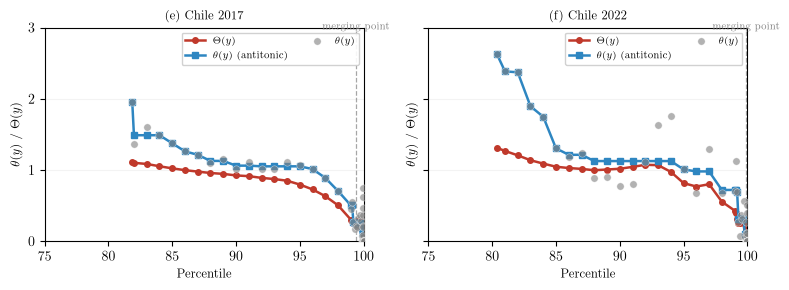

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8), sharey=True)
for ax, (name, r) in zip(axes, results.items()):
    pct = 100 * fractal_percentiles_from(r["p_start"])[:-1]
    plot_bfm_theta_Theta_real(fig, ax, r["tilde"], r["theta_hat"], r["Theta_hat"], r["yk"],
                              r["tax_share"], pct=pct, title=f"({'e' if name=='2017' else 'f'}) Chile {name}")
plt.subplots_adjust(left=0.07, right=0.97, top=0.92, bottom=0.14, wspace=0.15)
save_fig(ROOT / "figures/p3/bfm_theta_Theta_real.pdf", fig)
plt.show()
